# Portal da Transparência, Recursos transferidos — civil-defence extract (br-transparencia-transferencias, 2026-07)

Source: CGU monthly bulk downloads `sample/2026MM_Transferencias.zip`, January–July 2026 (re-download steps in the review README). Review README: `../../README.md` · Need: `2026-09-br-finance-pathways-review` (Route E, civil-defence and disaster finance).
Purpose: filter the federal civil-defence transfers (MIDR órgão 53000, ações 22BO and 8348) into one typed, bilingual pipeline-ready table, assert it against the README profile, and answer the need's fit questions inline. English descriptions are paired with the original Portuguese in `*_pt` fields; legal entity and place names remain untranslated and are explicitly marked. Restart-and-run-all must pass before commit.

In [1]:
import glob, hashlib, os, unicodedata, re, zipfile
from decimal import Decimal
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Parameters (release-specific inputs; become Mage pipeline variables)
RELEASE = "2026-07"
RAW_GLOB = "sample/2026*_Transferencias.zip"
DATA = "data"
OUT = "sample/br_transparencia_transferencias_civil_defence_payments.csv"
TARGET_ORGAN = "53000"             # MIDR, unidades com vínculo direto
TARGET_ACTIONS = ["22BO", "8348"]  # response & recovery / emergency mitigation works
IBGE_REF = "../../../../br-ibge/br-munic/releases/2020-2021/data/br_munic_finance_push.csv"  # used only in fit cell 6.5

os.makedirs(DATA, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "axes.axisbelow": True})
COLOR = {"22BO": "#2e7d52", "8348": "#c07a12"}   # validated categorical pair (dataviz validator, light mode)
raw_paths = sorted(glob.glob(RAW_GLOB))
print(len(raw_paths), "monthly files:", [os.path.basename(p)[:6] for p in raw_paths])

7 monthly files: ['202601', '202602', '202603', '202604', '202605', '202606', '202607']


## 1. Load raw — zero transformations

Parsing note (file format): each ZIP holds one CP1252, semicolon-delimited, fully quoted CSV with 36 columns. Parsing note (identifiers): every field is read as text (`dtype=str`, `keep_default_na=False`) so leading zeros, `MU`, `-1`, `-14` and empty strings survive exactly as published. The only addition is `source_file`, for provenance. No PII: every payee is a public body (asserted in §4).

In [2]:
def load_monthly_zip(path):
    with zipfile.ZipFile(path) as zf:
        members = zf.namelist()
        assert len(members) == 1, f"{path}: expected one CSV, found {members}"
        with zf.open(members[0]) as fh:
            frame = pd.read_csv(fh, sep=";", encoding="cp1252", dtype=str, keep_default_na=False)
    frame["source_file"] = os.path.basename(path)
    return frame

raw = pd.concat([load_monthly_zip(p) for p in raw_paths], ignore_index=True)
print(raw.shape)
raw.head(2)

(1056421, 37)


,ANO / MÊS,TIPO TRANSFERÊNCIA,TIPO FAVORECIDO,UF,CÓDIGO MUNICÍPIO SIAFI,NOME MUNICÍPIO,CÓDIGO ÓRGÃO SIAFI,NOME ÓRGÃO,CÓDIGO UNIDADE GESTORA,NOME UNIDADE GESTORA,...,CÓDIGO SUBTÍTULO,NOME SUBTÍTULO,CÓDIGO LOCALIZADOR,NOME LOCALIZADOR,SIGLA LOCALIZADOR,DESCRIÇÃO COMPLEMENTAR LOCALIZADOR,CÓDIGO FAVORECIDO,NOME FAVORECIDO,VALOR TRANSFERIDO,source_file
0,202601,Constitucionais e Royalties,Administração Pública Estadual ou do Distrito ...,AC,,,-1,Sem informação,-1,Sem informação,...,-1,Sem informaç,-1,Sem informaç,,,63606479000124,ESTADO DO ACRE,"554516181,56",202601_Transferencias.zip
1,202601,Constitucionais e Royalties,Administração Pública Estadual ou do Distrito ...,AC,,,-1,Sem informação,-1,Sem informação,...,-1,Sem informaç,-1,Sem informaç,,,63606479000124,ESTADO DO ACRE,"159865,02",202601_Transferencias.zip


## 2. Clean — one parsing note per block

### 2.1 Filter by codes, not names
Parsing note: filter on `CÓDIGO ÓRGÃO SIAFI = 53000` and `AÇÃO IN (22BO, 8348)`; names vary in accents, casing and truncation.

In [3]:
is_target = raw["CÓDIGO ÓRGÃO SIAFI"].eq(TARGET_ORGAN) & raw["AÇÃO"].isin(TARGET_ACTIONS)
target = raw.loc[is_target].reset_index(drop=True)
target.groupby(["ANO / MÊS", "AÇÃO"]).size().unstack(fill_value=0)

AÇÃO,22BO,8348
ANO / MÊS,,
202601,42,0
202602,93,1
202603,67,1
202604,113,1
202605,192,0
202606,120,0
202607,113,0


### 2.2 Rename columns to snake_case
Parsing note: source headers carry accents, spaces and a slash; the working frame uses the snake_case names below. The release export is rebuilt by `build_bilingual_release.py`, which pairs English descriptions with original Portuguese `*_pt` values using an exact release-scoped dictionary.

In [4]:
RENAME = {
    "ANO / MÊS": "transfer_year_month", "TIPO TRANSFERÊNCIA": "transfer_type", "TIPO FAVORECIDO": "beneficiary_type",
    "UF": "uf", "CÓDIGO MUNICÍPIO SIAFI": "siafi_municipality_code", "NOME MUNICÍPIO": "municipality_name",
    "CÓDIGO ÓRGÃO SIAFI": "organ_code", "NOME ÓRGÃO": "organ_name",
    "CÓDIGO UNIDADE GESTORA": "managing_unit_code", "NOME UNIDADE GESTORA": "managing_unit_name",
    "CÓDIGO FUNÇÃO": "function_code", "NOME FUNÇÃO": "function_name",
    "CÓDIGO SUBFUNÇÃO": "subfunction_code", "NOME SUBFUNÇÃO": "subfunction_name",
    "CÓDIGO PROGRAMA": "program_code", "NOME PROGRAMA": "program_name",
    "AÇÃO": "action_code", "NOME AÇÃO": "action_name", "LINGUAGEM CIDADÃ": "citizen_language_label",
    "CÓDIGO GRUPO DESPESA": "expense_group_code", "NOME GRUPO DESPESA": "expense_group_name",
    "CÓDIGO MODALIDADE APLICAÇÃO DESPESA": "application_modality_code",
    "NOME MODALIDADE APLICAÇÃO DESPESA": "application_modality_name",
    "CÓDIGO ELEMENTO DESPESA": "expense_element_code", "NOME ELEMENTO DESPESA": "expense_element_name",
    "CÓDIGO PLANO ORÇAMENTÁRIO": "budget_plan_code", "NOME PLANO ORÇAMENTÁRIO": "budget_plan_name",
    "CÓDIGO SUBTÍTULO": "subtitle_code", "NOME SUBTÍTULO": "subtitle_name",
    "CÓDIGO LOCALIZADOR": "localizer_code", "NOME LOCALIZADOR": "localizer_name",
    "SIGLA LOCALIZADOR": "localizer_acronym", "DESCRIÇÃO COMPLEMENTAR LOCALIZADOR": "localizer_complement",
    "CÓDIGO FAVORECIDO": "beneficiary_code", "NOME FAVORECIDO": "beneficiary_name",
    "VALOR TRANSFERIDO": "amount_transferred_raw", "source_file": "source_file",
}
missing = [c for c in RENAME if c not in target.columns]
assert not missing, f"missing source columns: {missing}"
renamed = target.rename(columns=RENAME)[list(RENAME.values())]
renamed.columns.tolist()[:8]

['transfer_year_month',
 'transfer_type',
 'beneficiary_type',
 'uf',
 'siafi_municipality_code',
 'municipality_name',
 'organ_code',
 'organ_name']

### 2.3 Parse amounts as signed exact decimals
Parsing note: comma decimal separator, no thousands separator; keep the sign (reversals exist in the full files). `Decimal` carries the exact value for validation; the float column is for export and charts.

In [5]:
def parse_brl(text):
    return Decimal(text.replace(",", "."))

typed = renamed.copy()
typed["amount_transferred_decimal"] = typed["amount_transferred_raw"].map(parse_brl)
typed["amount_transferred_brl"] = typed["amount_transferred_decimal"].astype(float)
typed[["amount_transferred_raw", "amount_transferred_brl"]].head(3)

,amount_transferred_raw,amount_transferred_brl
0,"1168654,00",1168654.0
1,"302350,00",302350.0
2,"63806,40",63806.4


### 2.4 Flag aggregated classifications, keep raw sentinels
Parsing note: `Múltiplo`/`MU` marks rows aggregated across more than one budget classification; `-1`, `-14`, `Sem informação` and empty strings are kept as published. The only normalisation is one boolean flag, so downstream code does not have to re-learn the sentinels.

In [6]:
CLASSIFICATION_CODES = ["program_code", "expense_group_code", "application_modality_code",
                        "expense_element_code", "budget_plan_code", "subtitle_code", "localizer_code"]
CLASSIFICATION_NAMES = ["program_name", "expense_group_name", "application_modality_name",
                        "expense_element_name", "budget_plan_name", "subtitle_name", "localizer_name"]
clean = typed.copy()
clean["is_multiple_classification"] = (clean[CLASSIFICATION_CODES].isin(["MU", "-14"]).any(axis=1)
                                       | clean[CLASSIFICATION_NAMES].eq("Múltiplo").any(axis=1))
clean["is_multiple_classification"].value_counts()

is_multiple_classification
False    705
True      38
Name: count, dtype: int64

## 3. Validate — assertions (no export if any fail)

Layer 2 (structure) and the README profile as named expectations. Known source-side defects (truncated labels, the `REPOSTA` typo, placeholder MP numbers) are asserted as *present*, so a silent upstream fix or an accidental local "correction" both fail loudly.

In [7]:
# Source file: July hash matches the README record
july = [p for p in raw_paths if os.path.basename(p).startswith("202607")][0]
assert hashlib.md5(open(july, "rb").read()).hexdigest() == "14cc4c826bb836ff16aec4f33c3c1ab6"

# Whole-file structure: identical 36-column header, row counts per month, reversal and zero rows kept
assert raw.shape == (1_056_421, 37)
EXPECTED_ALL_ROWS = {"202601": 122_527, "202602": 106_663, "202603": 119_844, "202604": 180_836,
                     "202605": 241_393, "202606": 142_514, "202607": 142_644}
assert raw["ANO / MÊS"].value_counts().to_dict() == EXPECTED_ALL_ROWS
all_amounts = raw["VALOR TRANSFERIDO"].map(parse_brl)
sign_by_month = pd.DataFrame({"negative": all_amounts.lt(0), "zero": all_amounts.eq(0),
                              "month": raw["ANO / MÊS"]}).groupby("month")[["negative", "zero"]].sum()
assert sign_by_month.sum().to_dict() == {"negative": 706, "zero": 67}          # README corrected: 9/12 was July only
assert sign_by_month.loc["202607"].to_dict() == {"negative": 9, "zero": 12}

# Target slice: counts and exact sums per month and action (README data-profile table)
EXPECTED = {  # (month, action): (rows, exact R$)
    ("202601", "22BO"): (42, "34298173.35"),  ("202602", "22BO"): (93, "68971029.13"),
    ("202603", "22BO"): (67, "53044667.73"),  ("202604", "22BO"): (113, "106240748.58"),
    ("202605", "22BO"): (192, "148900511.33"), ("202606", "22BO"): (120, "76941943.40"),
    ("202607", "22BO"): (113, "86173368.23"),
    ("202602", "8348"): (1, "11994567.84"), ("202603", "8348"): (1, "277793.49"), ("202604", "8348"): (1, "9175511.98"),
}
observed = clean.groupby(["transfer_year_month", "action_code"])["amount_transferred_decimal"].agg(["size", "sum"])
assert set(observed.index) == set(EXPECTED), set(observed.index) ^ set(EXPECTED)
for key, (rows, total) in EXPECTED.items():
    assert observed.loc[key, "size"] == rows and observed.loc[key, "sum"] == Decimal(total), (key, observed.loc[key])
assert len(clean) == 743 and (clean["amount_transferred_decimal"] > 0).all()

# Structural constants for this release
assert clean["managing_unit_code"].eq("530012").all()
assert clean["beneficiary_type"].str.startswith("Administração Pública").all()   # public payees only, no PII
assert clean["beneficiary_code"].str.fullmatch(r"\d{14}").all()                   # CNPJs keep leading zeros
assert clean["citizen_language_label"].eq("Sem informação").all()
assert clean["municipality_name"].eq("").sum() == 12
assert clean.loc[clean["municipality_name"].eq(""), "beneficiary_type"].ne("Administração Pública Municipal").all()
assert clean.loc[clean["action_code"] == "22BO", "uf"].nunique() == 25
assert clean.loc[clean["action_code"] == "22BO", "beneficiary_code"].nunique() == 530
assert clean["budget_plan_name"].eq("Múltiplo").sum() == 37
assert clean["is_multiple_classification"].sum() == 38   # the 37 above + Vera Mendes/PI 8348 (MU group/modality/element)

# Grain: no exact duplicates; within a month the 35 non-value fields are unique
key_cols = [c for c in RENAME.values() if c not in ("amount_transferred_raw", "source_file")]
assert not clean.duplicated(key_cols + ["amount_transferred_raw"]).any()
assert not clean.duplicated(key_cols).any()

# Known source defects are preserved, not corrected
assert clean["subtitle_name"].str.len().max() == 57 and clean["localizer_name"].str.len().max() == 45
assert clean["budget_plan_name"].str.contains("REPOSTA").any()
assert clean["budget_plan_name"].str.contains("XXXXX").any()
print("ALL ASSERTIONS PASSED")

ALL ASSERTIONS PASSED


## 4. Export — one tidy, bilingual pipeline-ready table to `data/`

One row per month × payee × full budget classification, the amount as a number, the aggregation flag, and the source file. `build_bilingual_release.py` is the authoritative exporter: English descriptions are paired with source Portuguese in `*_pt` columns, source proper names are preserved in both paired fields, and explicit translation-status fields distinguish those cases. The exact `Decimal` helper column is not exported; `amount_transferred_raw` keeps the published string.

In [8]:
import build_bilingual_release as bilingual
bilingual.main()
export = pd.read_csv(OUT, dtype=str, keep_default_na=False)
assert len(export) == len(clean) and export["beneficiary_code"].str.len().eq(14).all()
assert export["translation_status"].eq("complete_exact_release_dictionary").all()
assert export["action_name_pt"].str.contains("ACOES").all()
print(export.shape, round(os.path.getsize(OUT) / 1024, 1), "KB", OUT, "| SHA256", hashlib.sha256(open(OUT, "rb").read()).hexdigest()[:16])

562.7 KB sample/br_transparencia_transferencias_civil_defence_payments.csv | SHA256 03abc9e6d0f5121d


## 5. Aggregates (in memory) — built for charting and the fit cells, not exported

In [9]:
clean["month"] = pd.to_datetime(clean["transfer_year_month"], format="%Y%m").dt.strftime("%b %Y")
month_order = clean.drop_duplicates("transfer_year_month").sort_values("transfer_year_month")["month"].tolist()
by_month = (clean.pivot_table(index="month", columns="action_code", values="amount_transferred_brl",
                              aggfunc="sum", fill_value=0).reindex(month_order) / 1e6)
by_uf = (clean.groupby("uf").agg(rows=("action_code", "size"), brl_m=("amount_transferred_brl", "sum"))
         .assign(brl_m=lambda d: d["brl_m"] / 1e6).sort_values("brl_m"))
by_month.round(1)

action_code,22BO,8348
month,,
Jan 2026,34.3,0.0
Feb 2026,69.0,12.0
Mar 2026,53.0,0.3
Apr 2026,106.2,9.2
May 2026,148.9,0.0
Jun 2026,76.9,0.0
Jul 2026,86.2,0.0


## 6. Visualise & fit

Only the questions the need raises: what the amounts mean over time, where they go, whether a row is a project (native record id), whether the route can be split, and whether the geography joins to IBGE.

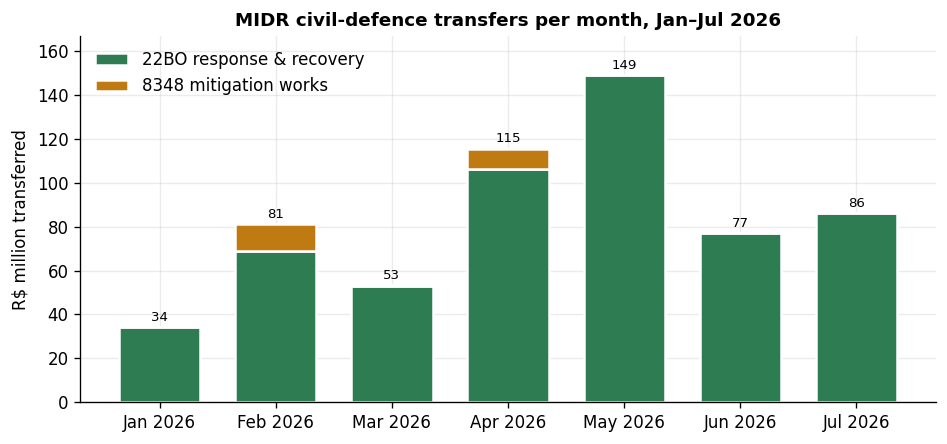

In [10]:
# 6.1 What the amounts are: monthly transferred cash, by action
fig, ax = plt.subplots(figsize=(8, 3.8))
bottom = pd.Series(0.0, index=by_month.index)
for action, label in [("22BO", "22BO response & recovery"), ("8348", "8348 mitigation works")]:
    ax.bar(by_month.index, by_month[action], bottom=bottom, color=COLOR[action], label=label,
           edgecolor="white", linewidth=1.5, width=.7)
    bottom += by_month[action]
for x, total in zip(by_month.index, bottom):
    ax.annotate(f"{total:,.0f}", (x, total), ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
ax.set_title("MIDR civil-defence transfers per month, Jan–Jul 2026"); ax.set_ylim(0, bottom.max() * 1.12)
ax.set_ylabel("R$ million transferred"); ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); plt.show()

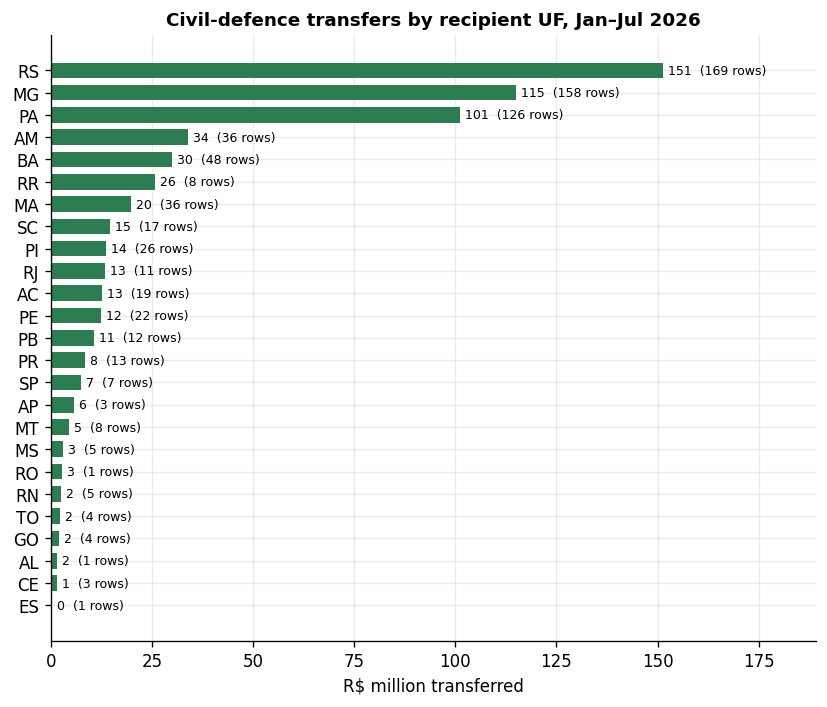

In [11]:
# 6.2 Where it goes: transferred amount by recipient UF (both actions)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(by_uf.index, by_uf["brl_m"], color=COLOR["22BO"], height=.7)
for y, (value, rows) in enumerate(zip(by_uf["brl_m"], by_uf["rows"])):
    ax.annotate(f"{value:,.0f}  ({rows} rows)", (value, y), va="center", fontsize=7.5, xytext=(3, 0), textcoords="offset points")
ax.set_title("Civil-defence transfers by recipient UF, Jan–Jul 2026")
ax.set_xlabel("R$ million transferred"); ax.set_xlim(0, by_uf["brl_m"].max() * 1.25)
fig.tight_layout(); plt.show()

### 6.3 Fit: is a row a project? (must-have `native_record_id`)
The files carry no portaria, process, agreement or payment-document number. The best available key is payee + full budget classification; the cell counts how often that key recurs across months, which is the ambiguity any project count would inherit.

keys: 677 | recurring keys: 58 | extra monthly observations: 66


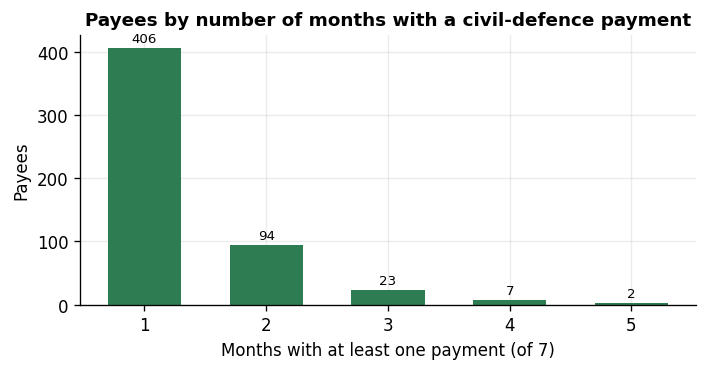

,keys
months_with_payment,
1,619
2,50
3,8


In [12]:
recurrence = clean.groupby(key_cols[1:]).size()   # drop transfer_year_month from the key
months_per_key = recurrence.value_counts().sort_index().rename_axis("months_with_payment").to_frame("keys")
payee_months = clean.groupby("beneficiary_code")["transfer_year_month"].nunique().value_counts().sort_index()
print("keys:", len(recurrence), "| recurring keys:", (recurrence > 1).sum(),
      "| extra monthly observations:", int((recurrence - 1).sum()))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(payee_months.index.astype(str), payee_months.values, color=COLOR["22BO"], width=.6)
for x, v in zip(payee_months.index.astype(str), payee_months.values):
    ax.annotate(str(v), (x, v), ha="center", va="bottom", fontsize=8, xytext=(0, 2), textcoords="offset points")
ax.set_title("Payees by number of months with a civil-defence payment")
ax.set_xlabel("Months with at least one payment (of 7)"); ax.set_ylabel("Payees")
fig.tight_layout(); plt.show()
months_per_key

### 6.4 Fit: can the route be split? (pathway separation)
Prevention separates from response and recovery at the action level (8348 vs 22BO). Inside 22BO the only candidate is the budget plan; the cell shows how the 22BO amount distributes over plan labels, grouped by what the label says about the disaster phase.

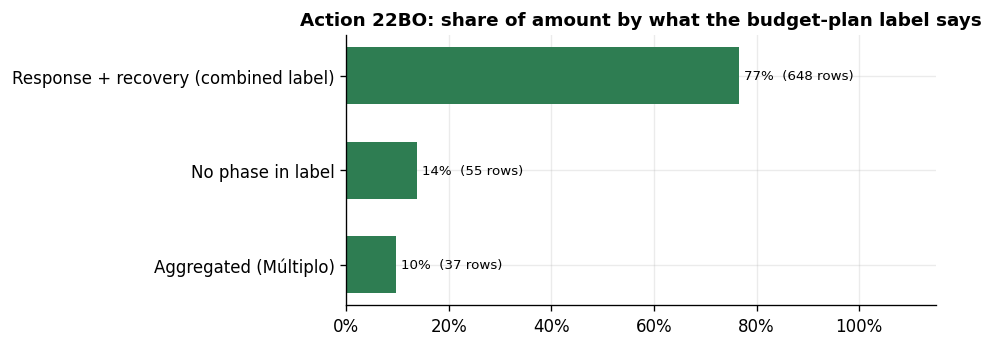

rows
plan_phase                           budget_plan_name                                        
Aggregated (Múltiplo)                Múltiplo                                              37
No phase in label                    CALAMIDADE PUBLICA - MEDIDA PROVISORIA N. 1.218...    27
                                     MEDIDA PROVISORIA N. 1.102 DE 24 DE FEVEREIRO D...     3
                                     MEDIDA PROVISORIA N. 1.180, DE 14 DE JULHO DE 2...     4
                                     MEDIDA PROVISORIA N. 1.188 DE 19 DE SETEMBRO DE...     1
                                     MEDIDA PROVISORIA N. 1.191 DE 25 DE OUTUBRO DE ...     4
                                     MEDIDA PROVISORIA N. 1.204, DE 29 DE DEZEMBRO D...     3
                                     MEDIDA PROVISORIA N. 1.214 DE 29 DE ABRIL DE 20...    13
Response + recovery (combined label) ACOES DE RESPOSTA E DE RECUPERACAO DE INFRAESTR...    36
                                     CALAMIDADE PUBLICA - MEDIDA PROVISORIA N. 1.244...    23
                                     CALAMIDADE PUBLICA - MEDIDA PROVISORIA N. 1.265...    27
                                     EMERGENCIA CLIMATICA (ADPF N. 743) - MEDIDA PRO...     7
                                     MEDIDA PROVISORIA N. 1.279, DE 16 DE DEZEMBRO D...     6
                                     MEDIDA PROVISORIA N. 1.299 DE 09 DE MAIO DE 202...    60
                                     MEDIDA PROVISORIA N. XXX, DE XX DE ABRIL DE 202...   147
                                     MEDIDA PROVISORIA N. XXX, DE XX DE DEZEMBRO DE ...    71
                                     MEDIDA PROVISORIA N. XXXX, DE XX DE DEZEMBRO DE...    28
                                     MEDIDA PROVISORIA N. XXXXX, DE XX DE MAIO DE 20...   243

In [13]:
def plan_phase(name):
    n = name.upper()
    if name == "Múltiplo":
        return "Aggregated (Múltiplo)"
    has_resp, has_rec = ("RESPOSTA" in n or "REPOSTA" in n), "RECUPERA" in n
    if has_resp and has_rec:
        return "Response + recovery (combined label)"
    if has_resp:
        return "Response only"
    if has_rec:
        return "Recovery only"
    return "No phase in label"

bo = clean[clean["action_code"] == "22BO"].assign(plan_phase=lambda d: d["budget_plan_name"].map(plan_phase))
phase = (bo.groupby("plan_phase").agg(rows=("plan_phase", "size"), brl_m=("amount_transferred_brl", "sum"))
         .assign(brl_m=lambda d: d["brl_m"] / 1e6, share=lambda d: d["brl_m"] / d["brl_m"].sum()).sort_values("brl_m"))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(phase.index, phase["share"], color=COLOR["22BO"], height=.6)
for y, (s, r) in enumerate(zip(phase["share"], phase["rows"])):
    ax.annotate(f"{s:.0%}  ({r} rows)", (s, y), va="center", fontsize=8, xytext=(3, 0), textcoords="offset points")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlim(0, 1.15)
ax.set_title("Action 22BO: share of amount by what the budget-plan label says")
fig.tight_layout(); plt.show()
bo.groupby(["plan_phase", "budget_plan_name"]).size().rename("rows").to_frame()

### 6.5 Fit: does the recipient geography join to IBGE? (must-have `recipient_geography`)
SIAFI municipality codes are not IBGE codes. The test here is the need's fallback, "name + UF that joins": fold accents and punctuation on both sides and join to the IBGE municipality list already in the repo (`br-munic`). The crosswalk itself belongs to Phase C, not to this table.

In [14]:
def fold_name(text):
    ascii_text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().upper()
    return re.sub(r"[^A-Z0-9]", "", ascii_text)

ibge = pd.read_csv(IBGE_REF, dtype=str, usecols=["cod_mun", "mun_name", "uf"])
ibge["join_key"] = ibge["uf"] + "|" + ibge["mun_name"].map(fold_name)
assert ibge["join_key"].is_unique

siafi_places = (clean.loc[clean["municipality_name"] != "", ["uf", "siafi_municipality_code", "municipality_name"]]
                .drop_duplicates().assign(join_key=lambda d: d["uf"] + "|" + d["municipality_name"].map(fold_name)))
assert siafi_places.groupby("siafi_municipality_code").size().max() == 1   # one name per SIAFI code
joined = siafi_places.merge(ibge[["join_key", "cod_mun"]], on="join_key", how="left")
print(f"{joined['cod_mun'].notna().sum()} of {len(joined)} SIAFI municipalities join to IBGE by folded name + UF")
assert set(phase.index) == {"Response + recovery (combined label)", "No phase in label", "Aggregated (Múltiplo)"}  # no single-phase label
joined.loc[joined["cod_mun"].isna(), ["uf", "siafi_municipality_code", "municipality_name"]]

523 of 526 SIAFI municipalities join to IBGE by folded name + UF


,uf,siafi_municipality_code,municipality_name
156,RJ,5875,PARATI
216,PA,0377,ELDORADO DOS CARAJAS
497,PA,0529,SANTA ISABEL DO PARA


## 7. Findings

**Extraction.** 743 civil-defence payment rows (740 under 22BO, 3 under 8348) from 1,056,421 rows in seven monthly files; every count and exact sum in the README profile table reproduces. The payment table is held locally, not committed because its reuse terms are unresolved: `sample/br_transparencia_transferencias_civil_defence_payments.csv`: English descriptions paired with source Portuguese in `*_pt` fields, exact source amounts, an analysis-ready BRL amount, the aggregation flag, translation-status fields and source-file provenance.

**Flowed back to the README.**
- Correction: the seven files hold 706 negative and 67 zero amounts, not 9 and 12 (those are July only). Most negatives are constitutional transfers; none fall in the target slice.
- The aggregation flag marks 38 rows, not 37: the 37 `Múltiplo` budget-plan rows plus Vera Mendes/PI (8348, March), which has a single plan but `MU` expense group, modality and element.

**Fit against the need's must-haves.**
- `native_record_id`: fail. The best available key (payee + full classification) gives 677 keys; 58 recur across months (66 extra monthly rows) and 126 of 532 payees were paid in two or more months. Rows are payment evidence, not projects.
- Route split: prevention vs response/recovery separates cleanly by action. Inside 22BO no label names a single phase: 77% of the amount sits under combined response-and-recovery labels, 14% under labels naming only a Medida Provisória, 10% under `Múltiplo`.
- `recipient_geography`: conditional pass. 523 of 526 SIAFI municipalities join to IBGE by accent-folded name + UF; the three misses are spelling variants (Parati/Paraty, Eldorado dos/do Carajás, Santa Isabel/Izabel do Pará). The 12 state-level rows stay at UF.
- `amount_with_meaning` and `stage_and_date`: pass at month grain. Amounts are cash transferred in the month, not authorised or project totals.
- `link_to_other_sources`: fail in this dataset. The despesas execution files (empenho level) carry `Processo`, `Observação` and `Código Convênio`, which are the likely route to Sedec portarias; unanswered until profiled.

**Concentration.** RS, MG and PA take about 62% of the R$ 596 million transferred in January–July 2026.